<a href="https://colab.research.google.com/github/NSPFD/Thai-quantum-computing-2026/blob/main/MyQLM_Basics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ⚛️ MyQLM Basics: A Hands-On Introduction to Quantum Circuits
**Thai School of Quantum Computing 2026**

In this notebook you will build, run and *understand* your first quantum circuits with **MyQLM**, a free Python framework for writing and simulating quantum programs. No prior quantum-programming experience is needed.

### 🗺️ Contents

| Section | Topic | Level |
|---|---|---|
| 1–2 | Welcome and essential quantum concepts | ⭐ Core |
| 3 | The MyQLM workflow | ⭐ Core |
| 4 | Experiment 1: the **X** gate | ⭐ Core |
| 5 | Experiment 2: the **Hadamard (H)** gate | ⭐ Core |
| 6 | Experiment 3: the **Z** gate | 🟡 Optional |
| 7 | Visualising quantum circuits | ⭐ Core |
| 8 | Experiment 4: two qubits, **CNOT** and the Bell state | ⭐ Core |
| 9 | Probabilities, statevectors and finite shots | ⭐ Core |
| 10 | Mini-challenges | ⭐ Core |
| 11 | Extension: parameterised gates and **VQE** | 🔵 Extension (self-study) |
| 12 | Summary and next steps | ⭐ Core |
| 13 | Answer key | ✅ Check after you try |
| A | Appendix: a bigger 4-qubit circuit | 🔵 Extension (self-study) |

> 💡 **Tip:** open the **table of contents** (☰ icon in the left sidebar of Colab) to jump between sections.

### 🏷️ Cell labels used in this notebook

| Label | Meaning |
|---|---|
| ▶️ **Run this cell** | Just execute it (`Shift + Enter`) and read the output. |
| 🤔 **Predict before running** | Write down what you expect *first*, then run the cell. |
| ✋ **Your turn** | Edit the code yourself and re-run. |
| ✅ **Solution** | Answers live in Section 13 (Answer key) at the end. Try first! |

---
# 1. Welcome and learning objectives

**MyQLM** is a free Python framework for writing, simulating and optimising quantum programs. It is developed by Eviden (formerly Atos). Its programs are written in Python, so you can use all the tools you already know (NumPy, Matplotlib, …).

### 🎯 By the end of this notebook you will be able to
1. Explain what a **qubit** is and what the states $|0\rangle$ and $|1\rangle$ are.
2. Explain what a **quantum gate** does.
3. Write a MyQLM program: allocate qubits, apply gates, build a circuit, run a job and read the results.
4. Interpret **amplitudes** and **probabilities**.
5. Create **superposition** with the Hadamard gate and see what **X** and **Z** do.
6. Build a **Bell state** with H and CNOT and explain the idea of **entanglement**.
7. Tell **ideal probabilities** apart from **finite-shot** measurement results.
8. **Modify a circuit and predict** how its output changes.

### 🔄 The MyQLM workflow
Every program in this notebook follows the same six steps. Keep this picture in mind. We will return to it often.

```
 Program  ──►  Qubits  ──►  Gates  ──►  Circuit  ──►  Job  ──►  Simulator  ──►  Results
    │            │            │           │            │           │               │
 Program()    qalloc(n)    H(q[0])    to_circ()    to_job()   qpu.submit(job)   loop over samples
```

> 💻 **Important:** all examples run on a **simulator**, a classical program on the Colab computer that calculates what an ideal quantum computer would do. **No real quantum hardware is used.** One consequence: a simulator lets us *peek inside* the quantum state (its amplitudes), which a real quantum computer would not allow. We will point out each time we do this.

### ▶️ Setup (run both cells)
The first cell installs MyQLM (about 30 seconds in a fresh Colab session). The second imports everything we need and prints the installed version.

> If you see an import error after installing, use **Runtime → Restart session** and run the cells again from the import cell.

In [1]:
# Install MyQLM (NumPy and Matplotlib are already available in Colab)
!pip install -q myqlm

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from importlib.metadata import version

from qat.lang.AQASM import Program, H, X, Z, CNOT   # build programs and the gates we use
from qat.qpus import get_default_qpu                 # the simulator ("QPU")
from qat.core.printer import plot_in_notebook        # draws a circuit
from qat.core.simutil import wavefunction            # returns all amplitudes of a circuit

print("MyQLM version:", version("myqlm"))
print("Setup complete ✔")

MyQLM version: 1.14.0
Setup complete ✔


---
# 2. Essential quantum concepts

### 2.1 Bit vs. qubit
* A **classical bit** is either `0` or `1`.
* A **qubit** has two basis states, written $|0\rangle$ and $|1\rangle$ (read "ket zero" and "ket one"). Its general state is

$$|\psi\rangle = \alpha\,|0\rangle + \beta\,|1\rangle ,\qquad |\alpha|^2 + |\beta|^2 = 1 .$$

The numbers $\alpha$ and $\beta$ are called **amplitudes**. They are *complex numbers*, so they can be positive, negative, or have an imaginary part.

The two basis states are the vectors
$$|0\rangle = \begin{pmatrix}1\\0\end{pmatrix}, \qquad |1\rangle = \begin{pmatrix}0\\1\end{pmatrix}.$$
A fresh qubit always starts in $|0\rangle$.

### 2.2 Superposition
If both $\alpha$ and $\beta$ are non-zero, the qubit is in a **superposition** of $|0\rangle$ and $|1\rangle$.

> ⚠️ **Careful with analogies.** You may hear that "a qubit is a spinning coin that is heads and tails at the same time". This picture is useful only for the *measurement statistics*. It is misleading in two ways: a coin always has one hidden definite face, and a coin's weights can never be negative. A qubit is described by *amplitudes*, which can be negative or complex, and amplitudes can **cancel or reinforce each other** (*interference*). Interference is where quantum computing gets its power, and we will see a tiny example in Section 6.

### 2.3 Measurement and probability
When we **measure** a qubit we always obtain a definite result, `0` or `1`, never "something in between":

$$P(0) = |\alpha|^2 , \qquad P(1) = |\beta|^2 .$$

So the **amplitude** is *not* the probability. The probability is the **squared magnitude** of the amplitude.

### 2.4 Quantum gates
A **quantum gate** is an operation that changes the amplitudes of a qubit (or of several qubits). Every gate is reversible. Today we use four gates:

| Gate | What it does | Effect on basis states |
|---|---|---|
| **X** | "Quantum NOT": swaps the amplitudes of $\lvert 0\rangle$ and $\lvert 1\rangle$ | $\lvert 0\rangle \to \lvert 1\rangle$, $\lvert 1\rangle \to \lvert 0\rangle$ |
| **H** (Hadamard) | Creates an equal superposition | $\lvert 0\rangle \to \frac{\lvert 0\rangle+\lvert 1\rangle}{\sqrt2}$ |
| **Z** | Flips the sign (the *phase*) of the $\lvert 1\rangle$ amplitude | $\lvert 0\rangle \to \lvert 0\rangle$, $\lvert 1\rangle \to -\lvert 1\rangle$ |
| **CNOT** | Two qubits: flips the *target* if the *control* is $\lvert 1\rangle$ | $\lvert 10\rangle \to \lvert 11\rangle$, $\lvert 00\rangle \to \lvert 00\rangle$ |

As matrices acting on $(\alpha,\beta)^T$:
$$X=\begin{pmatrix}0&1\\1&0\end{pmatrix},\quad H=\frac1{\sqrt2}\begin{pmatrix}1&1\\1&-1\end{pmatrix},\quad Z=\begin{pmatrix}1&0\\0&-1\end{pmatrix}.$$

---
# 3. The MyQLM workflow

We will run the simplest possible program: **allocate one qubit and apply no gate at all**. This shows every step of the workflow, and it gives us a *baseline* to compare with later.

### What the imports mean (already done in the setup cell)

| Import | Purpose |
|---|---|
| `Program` | The "notebook" where we write our quantum instructions |
| `H, X, Z, CNOT` | The gates |
| `get_default_qpu` | Gives us a simulator to run our circuit on (QPU = *Quantum Processing Unit*) |
| `plot_in_notebook` | Draws a circuit diagram |
| `wavefunction` | Returns all amplitudes of the final state (simulator only) |

### Steps 1–2 · Create a program and allocate a qubit
▶️ **Run this cell**

In [3]:
prog = Program()          # 1. create an empty quantum program
q = prog.qalloc(1)        # 2. allocate ONE qubit; q is a register, q[0] is our qubit

print("Number of qubits allocated:", len(q))

Number of qubits allocated: 1


* `prog` is the program we are writing.
* `qalloc(1)` reserves one qubit. The result `q` behaves like a list, so `q[0]` is the first qubit. Later we will use `qalloc(2)` to get `q[0]` and `q[1]`.
* All qubits start in the state $|0\rangle$.

### Steps 3–4 · Convert to a circuit and create a job
▶️ **Run this cell**

In [4]:
circuit = prog.to_circ()  # 3. freeze the program into a circuit (a fixed list of gates)
job = circuit.to_job()    # 4. wrap the circuit in a job: a "request to run this circuit"

print("Qubits in the circuit:", circuit.nbqbits)
print("Shots in the job:", job.nbshots, " (0 means: compute the exact result, no random sampling)")

Qubits in the circuit: 1
Shots in the job: 0  (0 means: compute the exact result, no random sampling)


* A **circuit** is the finished list of gates. It cannot change any more.
* A **job** says *how* we want to run the circuit. By default (`nbshots=0`) the simulator computes the **exact** result. In Section 9 we will ask for a finite number of shots instead.

### Steps 5–7 · Choose a simulator, run the job, read the result
▶️ **Run this cell**

In [5]:
qpu = get_default_qpu()   # 5. choose the backend: a simulator running on this computer
result = qpu.submit(job)  # 6. run the job on the simulator

for sample in result:     # 7. read the result: one "sample" for each basis state that can occur
    print(f"state = {sample.state}   amplitude = {sample.amplitude:.3f}   probability = {sample.probability:.3f}")

state = |0>   amplitude = 1.000+0.000j   probability = 1.000


**Reading the output.** The result contains one **sample** per basis state that has non-zero probability:

* `sample.state`: the basis state, printed like `|0>` or `|11>`.
* `sample.amplitude`: its amplitude, a complex number (`+0.000j` means the imaginary part is zero).
* `sample.probability`: the probability of measuring that state.

Here there is a single sample, $|0\rangle$ with probability 1: with no gates, the qubit stays in $|0\rangle$. ✔️

> 📝 States with probability 0 are **not listed** in the result.

---
# 4. Experiment 1: the X gate

The **X gate** is the quantum version of NOT: it swaps the amplitudes of $|0\rangle$ and $|1\rangle$, so
$$X|0\rangle = |1\rangle .$$

### 🤔 Predict before running
In Section 3 the qubit with *no gate* gave $|0\rangle$ with probability 1. What will you see after adding an **X** gate?

▶️ **Run this cell**

In [6]:
prog = Program()
q = prog.qalloc(1)

X(q[0])                    # apply the X gate to qubit 0

circuit = prog.to_circ()
result = qpu.submit(circuit.to_job())

for sample in result:
    print(f"state = {sample.state}   amplitude = {sample.amplitude:.3f}   probability = {sample.probability:.3f}")

state = |1>   amplitude = 1.000+0.000j   probability = 1.000


**Expected output:** a single sample, state `|1>`, amplitude `1.000+0.000j`, probability `1.000`.

The X gate moved the qubit from $|0\rangle$ to $|1\rangle$ with certainty. Note how `X(q[0])` reads: *"apply gate X to qubit q[0]"*. The gate is recorded in the program that owns that qubit.

### ✋ Your turn
Add a **second** line `X(q[0])` right below the first one and re-run. What do you expect? *(Answer in Section 13 (Answer key).)*

---
# 5. Experiment 2: the Hadamard gate

The **Hadamard gate (H)** creates an *equal superposition*:

$$H|0\rangle = \frac{1}{\sqrt{2}}|0\rangle + \frac{1}{\sqrt{2}}|1\rangle \;\approx\; 0.707\,|0\rangle + 0.707\,|1\rangle .$$

### 🤔 Predict before running
Both amplitudes will be about $0.707$. Using $P = |\text{amplitude}|^2$, what probability do you expect for each outcome?

▶️ **Run this cell**

In [7]:
prog = Program()
q = prog.qalloc(1)

H(q[0])                    # apply the Hadamard gate to qubit 0

circuit = prog.to_circ()
result = qpu.submit(circuit.to_job())

for sample in result:
    print(f"state = {sample.state}   amplitude = {sample.amplitude:.3f}   "
          f"|amplitude|^2 = {abs(sample.amplitude)**2:.3f}   probability = {sample.probability:.3f}")

state = |0>   amplitude = 0.707+0.000j   |amplitude|^2 = 0.500   probability = 0.500
state = |1>   amplitude = 0.707+0.000j   |amplitude|^2 = 0.500   probability = 0.500


**Expected output:** two samples, `|0>` and `|1>`, each with amplitude `0.707+0.000j` and probability `0.500`.

### 💡 Amplitude vs. probability
| | Value here | Meaning |
|---|---|---|
| **Amplitude** | $0.707 = 1/\sqrt2$ | A (complex) number that describes the state. It can be negative. |
| **Probability** | $0.707^2 = 0.5$ | What we would actually see in measurements: $P = \lvert\text{amplitude}\rvert^2$ |

The last two columns of the output are equal. This is the rule from Section 2.3, checked by the code.

> ⚠️ This is a **definite quantum state**, with both amplitudes known exactly. It is *not* a qubit that secretly holds a random classical bit. The 50/50 describes what *measurements* will show. On a real device you could only learn it by repeating the experiment many times (Section 9).

### ✋ Your turn
Add a **second** `H(q[0])` line and re-run. Do you expect 50/50 again? *(Answer in Section 13 (Answer key).)*

---
# 6. Experiment 3: the Z gate
🟡 **Optional section**

The **Z gate** leaves $|0\rangle$ unchanged and flips the **sign** of the $|1\rangle$ amplitude. That sign is called a **phase**:

$$Z|0\rangle = |0\rangle, \qquad Z|1\rangle = -|1\rangle .$$

On its own, Z does nothing visible to $|0\rangle$. It becomes interesting when applied to a superposition.

### 🤔 Predict before running
Apply **H** and then **Z**. Will the *probabilities* change compared with H alone? What about the *amplitudes*?

▶️ **Run this cell**

In [8]:
prog = Program()
q = prog.qalloc(1)

H(q[0])                    # first: create the superposition
Z(q[0])                    # second: flip the sign of the |1> amplitude

circuit = prog.to_circ()
result = qpu.submit(circuit.to_job())

for sample in result:
    print(f"state = {sample.state}   amplitude = {sample.amplitude:.3f}   probability = {sample.probability:.3f}")

state = |0>   amplitude = 0.707+0.000j   probability = 0.500
state = |1>   amplitude = -0.707+0.000j   probability = 0.500


**Expected output:** `|0>` with amplitude `+0.707` and `|1>` with amplitude **`-0.707`**. Both probabilities are still `0.500`.

* Probabilities depend on $|\text{amplitude}|^2$, so the minus sign is **invisible** if we measure right now.
* But the sign is real information. Watch what happens when we apply **H again** after Z:

▶️ **Run this cell** (H, then Z, then H)

In [9]:
prog = Program()
q = prog.qalloc(1)

H(q[0])
Z(q[0])
H(q[0])                    # a second H turns the hidden sign into a visible difference

circuit = prog.to_circ()
result = qpu.submit(circuit.to_job())

for sample in result:
    print(f"state = {sample.state}   amplitude = {sample.amplitude:.3f}   probability = {sample.probability:.3f}")

state = |1>   amplitude = 1.000+0.000j   probability = 1.000


**Expected output:** `|1>` with probability `1.000`.

Without the Z in the middle, H followed by H returns to $|0\rangle$ (Section 5, "Your turn"). With Z in the middle the answer flips to $|1\rangle$. The two paths **interfere**: with one sign they cancel on $|1\rangle$, with the other sign they cancel on $|0\rangle$. This is **interference**, and algorithms such as Grover's and Shor's are built from it.

**Key idea:** a phase change does not alter immediate computational-basis probabilities, but it can change what later gates produce.

---
# 7. Visualising quantum circuits

Before building bigger circuits, let us learn to **read a circuit diagram**. We will draw a small 3-qubit circuit. Its only purpose is to practise reading: we will not analyse its output.

▶️ **Run this cell**

In [10]:
prog = Program()
q = prog.qalloc(3)

H(q[0])                    # H on qubit 0
X(q[1])                    # X on qubit 1
CNOT(q[0], q[2])           # CNOT: control = qubit 0, target = qubit 2

demo = prog.to_circ()
plot_in_notebook(demo)     # draw the circuit

### How to read the diagram
* Each **horizontal line (wire)** is one qubit, labelled **Q0, Q1, Q2 from top to bottom**.
* **Time flows from left to right.** Gates further to the left happen first. Gates drawn in the **same column** (here H and X) act at the same time, on different qubits.
* A **box** such as `H` or `X` is a one-qubit gate acting on the wire it sits on.
* A **CNOT** is drawn as a **dot ● on the control qubit** joined by a vertical line to a **⊕ on the target qubit**. Here the control is Q0 and the target is Q2.
* The vertical CNOT line **passes over Q1 but does not act on it**. Q1 only has the X gate.

### The same circuit as text
Sometimes a list is easier than a picture. This loop prints each gate, in order, with the qubit(s) it acts on. For a CNOT the **first** number is the control and the **second** is the target.

▶️ **Run this cell**

In [11]:
for gate_name, parameters, qubits in demo.iterate_simple():
    print(f"gate = {gate_name:<5}  acts on qubit(s) {qubits}")

gate = H      acts on qubit(s) [0]
gate = X      acts on qubit(s) [1]
gate = CNOT   acts on qubit(s) [0, 2]


**Expected output:**
```
gate = H      acts on qubit(s) [0]
gate = X      acts on qubit(s) [1]
gate = CNOT   acts on qubit(s) [0, 2]
```
🤔 **Quick check:** in this circuit, which qubit is the control, which is the target, and which qubit is never involved in the CNOT? *(Control: q[0]. Target: q[2]. Not involved: q[1].)*

---
# 8. Experiment 4: two qubits, CNOT and the Bell state

Now we use **two qubits**. The **CNOT** (controlled-NOT) gate has a *control* qubit and a *target* qubit:

> **If the control is $|1\rangle$, flip the target (apply X to it). If the control is $|0\rangle$, do nothing.**

### The Bell-state circuit
1. Start with both qubits in $|00\rangle$.
2. Apply **H** to qubit 0 → a superposition on qubit 0.
3. Apply **CNOT** with control = qubit 0 and target = qubit 1.

▶️ **Run this cell**

In [12]:
prog = Program()
q = prog.qalloc(2)

H(q[0])                    # step 1: put qubit 0 into superposition
CNOT(q[0], q[1])           # step 2: control = qubit 0, target = qubit 1

bell = prog.to_circ()
plot_in_notebook(bell)

### What happens, step by step
$$|00\rangle \;\xrightarrow{\;H \text{ on } q_0\;}\; \frac{|0\rangle+|1\rangle}{\sqrt2}\otimes|0\rangle = \frac{|00\rangle+|10\rangle}{\sqrt2} \;\xrightarrow{\;\text{CNOT}(q_0\to q_1)\;}\; \frac{|00\rangle+|11\rangle}{\sqrt2}$$

The CNOT leaves $|00\rangle$ alone (control is 0) but turns $|10\rangle$ into $|11\rangle$ (control is 1, so the target flips).

> 🔤 **State labels in MyQLM:** a label like `|10>` is written as `|q0 q1>`, so **qubit 0 is the leftmost character**. For example `|10>` means *q[0] = 1 and q[1] = 0*.

### 🤔 Predict before running
Which of the four states `|00>`, `|01>`, `|10>`, `|11>` will have non-zero probability, and how large?

▶️ **Run this cell**

In [13]:
result = qpu.submit(bell.to_job())

for sample in result:
    print(f"state = {sample.state}   amplitude = {sample.amplitude:.3f}   probability = {sample.probability:.3f}")

state = |00>   amplitude = 0.707+0.000j   probability = 0.500
state = |11>   amplitude = 0.707+0.000j   probability = 0.500


**Expected output:** only `|00>` and `|11>`, each with amplitude `0.707+0.000j` and probability `0.500`. This state is the **Bell state** $\frac{|00\rangle+|11\rangle}{\sqrt2}$.

* If you measure both qubits, you get `00` **or** `11`, each half of the time.
* You **never** get `01` or `10`. The two outcomes are perfectly **correlated**.

### What if we remove the CNOT?
Let us compare with a circuit that has the same H gate but **no CNOT**.

▶️ **Run this cell**

In [14]:
prog = Program()
q = prog.qalloc(2)

H(q[0])                    # only the Hadamard on qubit 0, no CNOT

no_cnot = prog.to_circ()
result = qpu.submit(no_cnot.to_job())

for sample in result:
    print(f"state = {sample.state}   amplitude = {sample.amplitude:.3f}   probability = {sample.probability:.3f}")

state = |00>   amplitude = 0.707+0.000j   probability = 0.500
state = |10>   amplitude = 0.707+0.000j   probability = 0.500


**Expected output:** `|00>` and `|10>`, each with probability `0.500`.

Qubit 0 is random (0 or 1) but **qubit 1 is always 0**. The qubits are **independent**. Compare:

| Circuit | Possible outcomes (q0 q1) | Relationship between the qubits |
|---|---|---|
| H only | `00`, `10` | Independent: q1 is always 0 |
| H + CNOT (Bell) | `00`, `11` | Perfectly correlated: q1 always equals q0 |

### 🧩 Why is the Bell state *entangled*?
The state $\frac{|00\rangle+|11\rangle}{\sqrt2}$ **cannot be written as a separate state for qubit 0 times a separate state for qubit 1**. The two qubits only have a joint description. This property is called **entanglement**.

> ⚠️ **Correlation alone is not proof of entanglement.** Two classical coins that are always glued to the same face also give "00 or 11". What makes the Bell state entangled is that it is a *single superposition* that does not factorise. Experiments confirm it by measuring in *other* bases, which is beyond today's lesson. Today we only check the *factorisation* property in the optional cell below.

### 🟡 Optional: a numerical test for entanglement (2 qubits)
Write a pure two-qubit state as $a_{00}|00\rangle + a_{01}|01\rangle + a_{10}|10\rangle + a_{11}|11\rangle$. It is a product of two single-qubit states **if and only if** $a_{00}\,a_{11} = a_{01}\,a_{10}$. (This is a simulator-only check, since it needs the amplitudes.)

▶️ **Run this cell**

In [15]:
for name, circ in [("H only (no CNOT)", no_cnot), ("Bell (H + CNOT)", bell)]:
    a = wavefunction(circ, qpu)                 # amplitudes in the order |00>, |01>, |10>, |11>
    difference = a[0] * a[3] - a[1] * a[2]      # a00*a11 - a01*a10
    print(f"{name:<18}  |a00*a11 - a01*a10| = {abs(difference):.3f}")

H only (no CNOT)    |a00*a11 - a01*a10| = 0.000
Bell (H + CNOT)     |a00*a11 - a01*a10| = 0.500


**Expected output:** `0.000` for "H only" (a product state, **not** entangled) and `0.500` for the Bell circuit (**entangled**).

---
# 9. Probabilities, statevectors and finite shots

So far we asked the simulator for the **exact** answer. Real experiments do not work like that. Here are the three ways of looking at a result, using the Bell circuit.

| What we ask for | What we get | Possible on real hardware? |
|---|---|---|
| `qpu.submit(circuit.to_job())` (`nbshots=0`) | **Exact** amplitudes and probabilities of the states that can occur | ❌ simulator only |
| `wavefunction(circuit, qpu)` | The **statevector**: all amplitudes, including the zeros | ❌ simulator only |
| `circuit.to_job(nbshots=N)` | **N simulated measurements**, giving observed frequencies | ✅ this is what hardware gives |

### 9.1 The statevector
The **statevector** lists the amplitude of *every* basis state. For $n$ qubits there are $2^n$ of them, in the order `|00>, |01>, |10>, |11>` for two qubits. It also shows the states with zero probability that the earlier loops skipped.

▶️ **Run this cell**

In [16]:
state = wavefunction(bell, qpu)       # a NumPy array with 2**n amplitudes
n = bell.nbqbits                      # number of qubits in the circuit (2 here)

for index, amplitude in enumerate(state):
    label = format(index, f"0{n}b")   # 0 -> '00', 1 -> '01', 2 -> '10', 3 -> '11'
    print(f"|{label}>   amplitude = {amplitude:.3f}   probability = {abs(amplitude)**2:.3f}")

|00>   amplitude = 0.707+0.000j   probability = 0.500
|01>   amplitude = 0.000+0.000j   probability = 0.000
|10>   amplitude = 0.000+0.000j   probability = 0.000
|11>   amplitude = 0.707+0.000j   probability = 0.500


**Expected output:** amplitudes `0.707` for `|00>` and `|11>`, `0.000` for `|01>` and `|10>`. Probabilities are the squared magnitudes: `0.500, 0.000, 0.000, 0.500`.

▶️ **Run this cell** to see the ideal probability distribution as a bar chart.

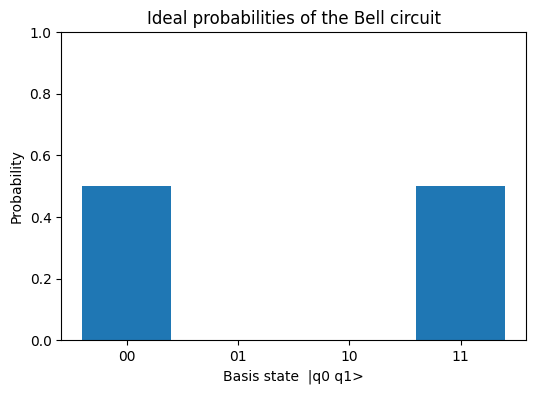

In [17]:
labels = [format(i, f"0{n}b") for i in range(2**n)]
ideal_probabilities = np.abs(state) ** 2

plt.figure(figsize=(6, 4))
plt.bar(labels, ideal_probabilities)
plt.xlabel("Basis state  |q0 q1>")
plt.ylabel("Probability")
plt.title("Ideal probabilities of the Bell circuit")
plt.ylim(0, 1)
plt.show()

### 9.2 Finite shots: what an experiment actually gives
On a real quantum computer you cannot read the amplitudes. You prepare the circuit, **measure all qubits** in the $|0\rangle/|1\rangle$ basis, and repeat many times. Each repetition is one **shot**. The fraction of times you saw each result is its **frequency**.

In MyQLM, `to_job(nbshots=N)` asks the simulator to **imitate N repeated measurements**. This is still a simulation, but it behaves like an experiment: *random*, and *without access to the amplitudes*.

▶️ **Run this cell** (100 shots)

In [18]:
shots = 100
result_shots = qpu.submit(bell.to_job(nbshots=shots))

for sample in result_shots:
    counts = round(sample.probability * shots)
    print(f"state = {sample.state}   count = {counts} out of {shots}   "
          f"frequency = {sample.probability:.2f}   statistical error ≈ {sample.err:.2f}")

state = |11>   count = 44 out of 100   frequency = 0.44   statistical error ≈ 0.05
state = |00>   count = 56 out of 100   frequency = 0.56   statistical error ≈ 0.05


**What to notice**
* With shots, `sample.probability` is the **observed frequency** (count ÷ shots), *not* the ideal probability.
* `sample.err` is an estimate of the **statistical uncertainty** on that frequency.
* There is **no amplitude** any more: a measurement never reveals it.
* The numbers are **random**. Re-run the cell and they will change, for example `|00>: 0.47`, `|11>: 0.53` instead of the ideal `0.50`.
* Only `|00>` and `|11>` ever appear, as predicted.

### 9.3 More shots → closer to the ideal
Let us repeat the experiment with different numbers of shots.

▶️ **Run this cell**

In [19]:
for shots in [10, 100, 1000, 10000]:
    result = qpu.submit(bell.to_job(nbshots=shots))

    frequencies = {}                                   # dictionary: state name -> observed frequency
    for sample in result:
        frequencies[str(sample.state)] = sample.probability

    line = f"shots = {shots:>5}   "
    for name in ["|00>", "|01>", "|10>", "|11>"]:
        line += f"{name}: {frequencies.get(name, 0):.4f}   "   # .get(..., 0): states never seen count as 0
    print(line)

shots =    10   |00>: 0.5000   |01>: 0.0000   |10>: 0.0000   |11>: 0.5000   
shots =   100   |00>: 0.5600   |01>: 0.0000   |10>: 0.0000   |11>: 0.4400   
shots =  1000   |00>: 0.5020   |01>: 0.0000   |10>: 0.0000   |11>: 0.4980   
shots = 10000   |00>: 0.4936   |01>: 0.0000   |10>: 0.0000   |11>: 0.5064   


**What to notice:** with 10 shots the frequencies can be far from $0.5$ (for example $0.3/0.7$). With 10 000 shots they are very close to $0.5$. The error shrinks roughly like $1/\sqrt{\text{shots}}$. The outputs differ on every run because sampling is random.

▶️ **Run this cell** to compare the *ideal* distribution with one 100-shot experiment.

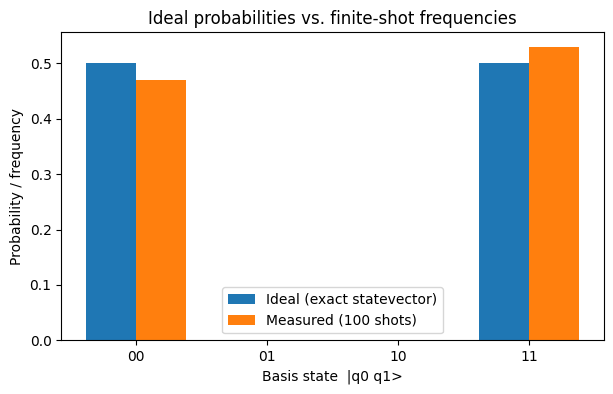

In [20]:
labels = [format(i, f"0{n}b") for i in range(2**n)]       # '00', '01', '10', '11'
ideal_probabilities = np.abs(state) ** 2                    # exact probabilities from the statevector

result_100 = qpu.submit(bell.to_job(nbshots=100))

frequencies_100 = {}
for sample in result_100:
    frequencies_100[str(sample.state)] = sample.probability

measured = [frequencies_100.get("|" + label + ">", 0) for label in labels]   # frequency of each state

x = np.arange(len(labels))
width = 0.38
plt.figure(figsize=(7, 4))
plt.bar(x - width/2, ideal_probabilities, width, label="Ideal (exact statevector)")
plt.bar(x + width/2, measured, width, label="Measured (100 shots)")
plt.xticks(x, labels)
plt.xlabel("Basis state  |q0 q1>")
plt.ylabel("Probability / frequency")
plt.title("Ideal probabilities vs. finite-shot frequencies")
plt.legend()
plt.show()

The blue bars are the **theory** (exact, from the statevector). The orange bars are what one **experiment** with 100 shots gives. They are similar, but not identical.

---
# 10. Mini-challenges

For **each** challenge:
1. 🤔 **Write down your prediction** first (on paper, or double-click this cell to type it).
2. ✋ Edit the **starter cell** below the challenge and run it.
3. Compare the output with your prediction and explain any difference.

✅ Solutions and explanations are in **Section 13 (Answer key)** at the end. Try before you look!

---
### Challenge 1: Remove H from the Bell circuit
Delete (or comment out with `#`) the `H(q[0])` line, keeping the CNOT. What are the possible outcomes and their probabilities?

✍️ **My prediction:** *(double-click to type)*

In [21]:
# CHALLENGE 1: remove or comment out the H line, then run
prog = Program()
q = prog.qalloc(2)

H(q[0])                    # <-- remove this line
CNOT(q[0], q[1])

circuit = prog.to_circ()
result = qpu.submit(circuit.to_job())

for sample in result:
    print(f"state = {sample.state}   amplitude = {sample.amplitude:.3f}   probability = {sample.probability:.3f}")

state = |00>   amplitude = 0.707+0.000j   probability = 0.500
state = |11>   amplitude = 0.707+0.000j   probability = 0.500


---
### Challenge 2: Replace H with X
Keep the CNOT, but apply **X** instead of **H** on qubit 0. What do you expect? Are the two qubits entangled?

✍️ **My prediction:** *(double-click to type)*

In [22]:
# CHALLENGE 2: replace H with X, keep the CNOT, then run
prog = Program()
q = prog.qalloc(2)

H(q[0])                    # <-- replace H with X
CNOT(q[0], q[1])

circuit = prog.to_circ()
result = qpu.submit(circuit.to_job())

for sample in result:
    print(f"state = {sample.state}   amplitude = {sample.amplitude:.3f}   probability = {sample.probability:.3f}")

state = |00>   amplitude = 0.707+0.000j   probability = 0.500
state = |11>   amplitude = 0.707+0.000j   probability = 0.500


---
### Challenge 3: Remove the CNOT
Keep the H gate but delete the `CNOT` line. Describe the resulting state in words. What does qubit 1 do?

✍️ **My prediction:** *(double-click to type)*

In [23]:
# CHALLENGE 3: remove or comment out the CNOT line, then run
prog = Program()
q = prog.qalloc(2)

H(q[0])
CNOT(q[0], q[1])           # <-- remove this line

circuit = prog.to_circ()
result = qpu.submit(circuit.to_job())

for sample in result:
    print(f"state = {sample.state}   amplitude = {sample.amplitude:.3f}   probability = {sample.probability:.3f}")

state = |00>   amplitude = 0.707+0.000j   probability = 0.500
state = |11>   amplitude = 0.707+0.000j   probability = 0.500


---
### Challenge 4: Design your own circuit
Create a circuit of your own using only the gates we met (**X, H, Z, CNOT**). You may change the number of qubits.

* First *predict* the outcome on paper, then run it.
* Ideas: make the state $|11\rangle$; make a state with 3 qubits where **all three** are correlated; use Z between two H gates.

✍️ **My circuit and prediction:** *(double-click to type)*

In [24]:
# CHALLENGE 4: your own circuit
prog = Program()
q = prog.qalloc(2)         # change the number of qubits if you like

# ---- add your gates here, for example:  H(q[0])   X(q[1])   CNOT(q[0], q[1]) ----

circuit = prog.to_circ()
result = qpu.submit(circuit.to_job())

for sample in result:
    print(f"state = {sample.state}   amplitude = {sample.amplitude:.3f}   probability = {sample.probability:.3f}")

state = |00>   amplitude = 1.000+0.000j   probability = 1.000


---
# 11. Optional extension: parameterised gates and VQE
🔵 **Extension** · self-study

The **Variational Quantum Eigensolver (VQE)** is a famous hybrid quantum-classical algorithm. We keep this section short and practical: first a gate with an adjustable angle, then a small VQE.

### 11.1 A gate with a knob: RY(θ)
Gates such as **RY(θ)** have a **parameter**, an angle. $\mathrm{RY}(\theta)|0\rangle = \cos\frac\theta2\,|0\rangle + \sin\frac\theta2\,|1\rangle$, so
$$P(0)=\cos^2\tfrac\theta2,\qquad P(1)=\sin^2\tfrac\theta2 .$$
Turning the knob θ smoothly moves the qubit between $|0\rangle$ and $|1\rangle$. This is the ingredient VQE uses.

▶️ **Run this cell**

In [25]:
from qat.lang.AQASM import RY

for theta in [0, np.pi/4, np.pi/2, np.pi]:
    prog = Program()
    q = prog.qalloc(1)
    RY(theta)(q[0])        # a gate with a parameter: first RY(angle), then apply it to a qubit
    state = wavefunction(prog.to_circ(), qpu)
    print(f"theta = {theta:.3f}   P(|0>) = {abs(state[0])**2:.3f}   P(|1>) = {abs(state[1])**2:.3f}")

theta = 0.000   P(|0>) = 1.000   P(|1>) = 0.000
theta = 0.785   P(|0>) = 0.854   P(|1>) = 0.146
theta = 1.571   P(|0>) = 0.500   P(|1>) = 0.500
theta = 3.142   P(|0>) = 0.000   P(|1>) = 1.000


▶️ **Run this cell** to sweep θ from 0 to 2π and plot the probabilities.

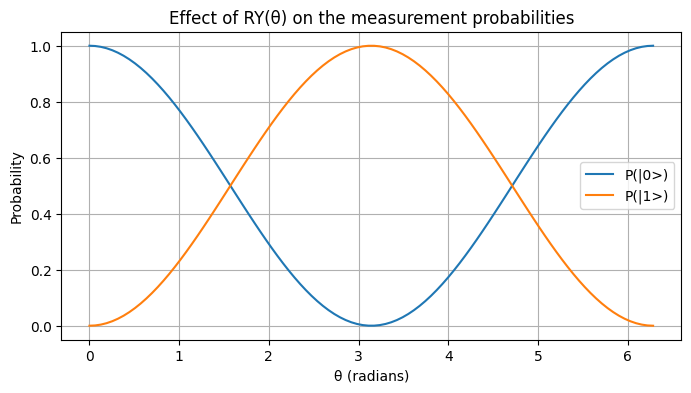

In [26]:
angles = np.linspace(0, 2*np.pi, 100)
p0 = []
p1 = []

for theta in angles:
    prog = Program()
    q = prog.qalloc(1)
    RY(theta)(q[0])
    state = wavefunction(prog.to_circ(), qpu)
    p0.append(abs(state[0])**2)
    p1.append(abs(state[1])**2)

plt.figure(figsize=(8, 4))
plt.plot(angles, p0, label="P(|0>)")
plt.plot(angles, p1, label="P(|1>)")
plt.xlabel("θ (radians)")
plt.ylabel("Probability")
plt.title("Effect of RY(θ) on the measurement probabilities")
plt.legend()
plt.grid(True)
plt.show()

### 11.2 VQE in plain language
**Goal:** find the *lowest energy* of a system. In quantum computing the energy is described by an **observable** (a "Hamiltonian").

VQE splits the work between two partners that loop until the energy stops decreasing:

```
        ┌────────────────────┐   angles θ     ┌─────────────────────────┐
        │  Classical         │ ─────────────► │  Quantum circuit        │
        │  optimiser         │                │  (+ simulator or QPU)   │
        │  (changes θ)       │ ◄───────────── │  (measures the energy)  │
        └────────────────────┘     energy     └─────────────────────────┘
```

| Part | Role |
|---|---|
| **Quantum circuit with angles** (the *ansatz*) | Prepares a state that depends on the adjustable angles θ |
| **Simulator / QPU** | Computes the energy of that state for the current θ |
| **Classical optimiser** | Looks at the energy and picks better angles |

In the example below, our energy observable is $Z\otimes Z + X\otimes X + Y\otimes Y$ on two qubits. Its lowest possible energy is **−3**, so we know what VQE should find.

In the code, `optimizer | qpu` connects the two partners into one *stack*. The `|` symbol means "feed this into that".

▶️ **Run this cell**

In [27]:
from qat.lang.AQASM import RY
from qat.core import Observable
from qat.plugins import ScipyMinimizePlugin

# 1. The energy (observable) we want to minimise
hamiltonian = (
    Observable.sigma_z(0) * Observable.sigma_z(1)
    + Observable.sigma_x(0) * Observable.sigma_x(1)
    + Observable.sigma_y(0) * Observable.sigma_y(1)
)

# 2. A circuit with two adjustable angles (the "ansatz")
prog = Program()
q = prog.qalloc(2)
theta0 = prog.new_var(float, "theta0")    # a variable that the optimiser will adjust
theta1 = prog.new_var(float, "theta1")

RY(theta0)(q[0])
RY(theta1)(q[1])
CNOT(q[0], q[1])
circuit = prog.to_circ()

# 3. A job that asks for the energy of this circuit
job = circuit.to_job(observable=hamiltonian)

# 4. The classical optimiser (COBYLA), starting from theta0 = theta1 = 0
optimizer = ScipyMinimizePlugin(method="COBYLA", tol=1e-6, options={"maxiter": 200}, x0=[0, 0])

# 5. Connect optimiser and simulator, then run VQE
stack = optimizer | qpu
vqe_result = stack.submit(job)

print(f"Minimum energy found: {vqe_result.value:.6f}   (exact answer: -3)")
print("Best angles:", vqe_result.meta_data["parameter_map"])

Minimum energy found: -3.000000   (exact answer: -3)
Best angles: {'theta0': -1.570796551332886, 'theta1': 3.141592729297564}


**Expected:** a minimum energy of about **−3.000000**. The optimiser found angles close to $\theta_0=-\pi/2\approx-1.571$ and $\theta_1=\pi\approx3.142$. Its energy matches the exact lowest value.

▶️ **Run this cell** to watch the energy decrease as the optimiser works.

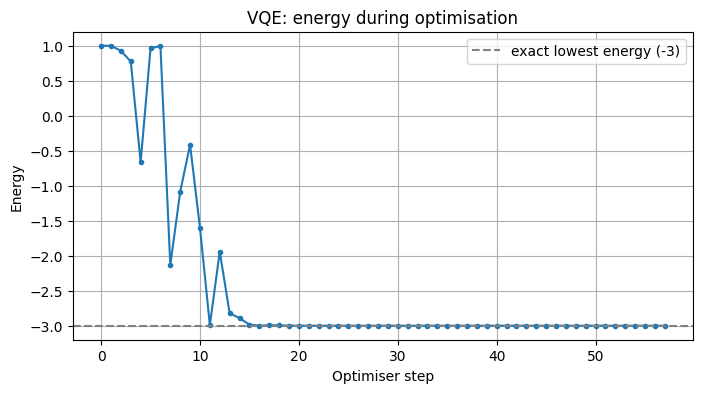

In [28]:
import json

energy_history = json.loads(vqe_result.meta_data["optimization_trace"])   # energy at each optimiser step

plt.figure(figsize=(8, 4))
plt.plot(energy_history, marker="o", markersize=3)
plt.axhline(-3, linestyle="--", color="gray", label="exact lowest energy (-3)")
plt.xlabel("Optimiser step")
plt.ylabel("Energy")
plt.title("VQE: energy during optimisation")
plt.legend()
plt.grid(True)
plt.show()

---
# 12. Summary and next steps

### ✅ What we learned
* A **qubit** has amplitudes $\alpha,\beta$ for $|0\rangle$ and $|1\rangle$. **Probabilities are squared magnitudes:** $P=|\text{amplitude}|^2$.
* **Gates** transform amplitudes: **X** swaps $|0\rangle\leftrightarrow|1\rangle$, **H** creates superposition, **Z** flips a phase (invisible on its own, but it matters for interference), **CNOT** flips a target conditioned on a control.
* The MyQLM workflow: **`Program` → `qalloc` → gates → `to_circ()` → `to_job()` → `qpu.submit(job)` → read the samples.**
* **H + CNOT** makes the **Bell state** $\frac{|00\rangle+|11\rangle}{\sqrt2}$: perfectly correlated outcomes, and an entangled state.
* **Exact results and statevectors** are simulator-only. **Finite-shot** results are what an experiment gives: random, and approaching the ideal probabilities as the number of shots grows.
* MyQLM prints state labels as `|q0 q1 …>`: **qubit 0 is the leftmost character**.

### 📖 Mini glossary

| Term | Meaning |
|---|---|
| **Qubit** | The basic unit of quantum information |
| **Basis states** | $\lvert0\rangle$ and $\lvert1\rangle$ |
| **Amplitude** | A complex number attached to a basis state |
| **Probability** | The squared magnitude of an amplitude |
| **Superposition** | A state with more than one non-zero amplitude |
| **Gate** | A reversible operation on qubits |
| **Phase** | The sign / complex angle of an amplitude |
| **Interference** | Amplitudes adding or cancelling |
| **Entanglement** | A multi-qubit state that cannot be written as separate states for each qubit |
| **Circuit** | An ordered list of gates |
| **Job** | A request to run a circuit (with options such as `nbshots`) |
| **QPU** | Quantum Processing Unit: real hardware or, here, a simulator |
| **Shot** | One repetition of "prepare and measure" |
| **Statevector** | The list of all $2^n$ amplitudes (simulator only) |

### 🧠 Three review questions
1. The H gate gives amplitudes of about 0.707. Why is the measurement probability 0.5 and not 0.707?
2. Adding a Z gate after H did not change the measurement probabilities. How could you show that it *did* change the state?
3. Why do 10 shots and 10 000 shots of the same circuit give different-looking results, and which one is closer to the ideal probabilities?

*(Answers in Section 13.)*

### 🔗 Next steps
* Official MyQLM documentation: **https://myqlm.github.io/01_getting_started.html**
* Try the optional VQE section (11) and the appendix (A) at your own pace.
* Experiment: build a 3-qubit circuit and predict its output before running it.

**Thank you, and enjoy exploring quantum programming!** ⚛️

---
# 13. Answer key
✅ **Stop!** Try the experiments, challenges and review questions yourself before reading on.

&nbsp;

&nbsp;

&nbsp;

### 13.1 Quick predictions from Sections 4 and 5
* **X twice** gives $|0\rangle$ again, with probability 1. X swaps $|0\rangle\leftrightarrow|1\rangle$, and applying the swap twice returns to the start (X is its own inverse).
* **H twice** also returns $|0\rangle$ with probability 1. The first H creates $\frac{|0\rangle+|1\rangle}{\sqrt2}$ and the second H makes the two paths **interfere**: the $|1\rangle$ contributions cancel and the $|0\rangle$ contributions add. So "H = 50/50" is true only when it acts on $|0\rangle$ or $|1\rangle$. On a superposition, H does something different. (H is also its own inverse.)

### 13.2 Challenge 1: Bell circuit without H

In [29]:
prog = Program()
q = prog.qalloc(2)

CNOT(q[0], q[1])           # no H: the control qubit stays |0>

circuit = prog.to_circ()
result = qpu.submit(circuit.to_job())

for sample in result:
    print(f"state = {sample.state}   amplitude = {sample.amplitude:.3f}   probability = {sample.probability:.3f}")

state = |00>   amplitude = 1.000+0.000j   probability = 1.000


**Result:** only `|00>`, probability 1.

**Why:** CNOT acts only when the control is $|1\rangle$. Without H, qubit 0 stays in $|0\rangle$, so the CNOT does nothing. There is no superposition and no entanglement.

### 13.3 Challenge 2: X instead of H

In [30]:
prog = Program()
q = prog.qalloc(2)

X(q[0])                    # q0 becomes |1>
CNOT(q[0], q[1])           # control is 1, so the target flips

circuit = prog.to_circ()
result = qpu.submit(circuit.to_job())

for sample in result:
    print(f"state = {sample.state}   amplitude = {sample.amplitude:.3f}   probability = {sample.probability:.3f}")

state = |11>   amplitude = 1.000+0.000j   probability = 1.000


**Result:** only `|11>`, probability 1.

**Why:** $|00\rangle \xrightarrow{X(q_0)} |10\rangle \xrightarrow{\text{CNOT}} |11\rangle$. The outcome is **perfectly correlated but completely deterministic**. This is a *product state* ($|1\rangle\otimes|1\rangle$) and is **not entangled**. It is a nice example of correlation without entanglement.

### 13.4 Challenge 3: H without CNOT

In [31]:
prog = Program()
q = prog.qalloc(2)

H(q[0])                    # no CNOT

circuit = prog.to_circ()
result = qpu.submit(circuit.to_job())

for sample in result:
    print(f"state = {sample.state}   amplitude = {sample.amplitude:.3f}   probability = {sample.probability:.3f}")

state = |00>   amplitude = 0.707+0.000j   probability = 0.500
state = |10>   amplitude = 0.707+0.000j   probability = 0.500


**Result:** `|00>` and `|10>`, each with probability 0.5.

**Why:** qubit 0 is in the superposition $\frac{|0\rangle+|1\rangle}{\sqrt2}$ and qubit 1 stays in $|0\rangle$:
$$\frac{|0\rangle+|1\rangle}{\sqrt2}\otimes|0\rangle .$$
This is a **product state**. Qubit 0's outcome is random, qubit 1 is always 0, and there is **no correlation and no entanglement**.

### 13.5 Challenge 4: a sample solution (3-qubit GHZ state)
There is no single right answer. Here is one natural extension of the Bell circuit to **three** qubits:

In [32]:
prog = Program()
q = prog.qalloc(3)

H(q[0])
CNOT(q[0], q[1])
CNOT(q[1], q[2])           # copy the correlation to the third qubit

circuit = prog.to_circ()
plot_in_notebook(circuit)

result = qpu.submit(circuit.to_job())
for sample in result:
    print(f"state = {sample.state}   amplitude = {sample.amplitude:.3f}   probability = {sample.probability:.3f}")

state = |000>   amplitude = 0.707+0.000j   probability = 0.500
state = |111>   amplitude = 0.707+0.000j   probability = 0.500


**Result:** `|000>` and `|111>`, each with probability 0.5. This is the **GHZ state** $\frac{|000\rangle+|111\rangle}{\sqrt2}$: all three qubits agree.

Other valid answers: `X(q[0])` then `CNOT(q[0], q[1])` gives `|11>`. `H, Z, H` on one qubit gives `|1>` (Section 6).

### 13.6 Review-question answers
1. **0.707 is the amplitude, not the probability.** The probability is the squared magnitude: $0.707^2 = 0.5$.
2. By applying **another H** afterwards (H, Z, H). The result is $|1\rangle$ with probability 1 instead of $|0\rangle$ (Section 6). The sign (phase) is hidden in a direct measurement but changes the outcome of later interference.
3. A finite number of shots is a *random sample*, so results fluctuate. The statistical error shrinks roughly like $1/\sqrt{\text{shots}}$, so **10 000 shots** is much closer to the ideal 0.5 than 10 shots.

---
# Appendix A: a bigger 4-qubit circuit
🔵 **Extension** · self-study

This is a larger example. It uses rotation gates with arbitrary angles, so the output is a "messy" but perfectly valid state spread over several basis states. Use it to practise reading circuits, gate statistics, statevectors and probability charts.

▶️ **Run this cell**

In [33]:
from qat.lang.AQASM import RX, RY

prog = Program()
q = prog.qalloc(4)

H(q[0])
RY(0.7)(q[1])              # rotation gates take an angle in radians
CNOT(q[0], q[1])
RX(0.4)(q[2])
CNOT(q[1], q[2])
CNOT(q[2], q[3])

big_circuit = prog.to_circ()
plot_in_notebook(big_circuit)

### Counting gates
The circuit object can report simple statistics.

▶️ **Run this cell**

In [34]:
print("Number of qubits:", big_circuit.nbqbits)
print("H gates   :", big_circuit.count("H"))
print("CNOT gates:", big_circuit.count("CNOT"))
print("RX gates  :", big_circuit.count("RX"))
print("RY gates  :", big_circuit.count("RY"))

print("\nCircuit statistics:")
print(big_circuit.statistics())

Number of qubits: 4
H gates   : 1
CNOT gates: 3
RX gates  : 1
RY gates  : 1

Circuit statistics:
{'nbqbits': 4, 'size': 6, 'gates': {'custom gate': 0, 'H': 1, 'RY': 1, 'CNOT': 3, 'RX': 1}, 'measurements': 0, 'resets': 0, 'logic': 0, 'breaks': 0, 'remaps': 0, 'gate_size': 6}


### Exact result and probability chart
Remember the label convention `|q0 q1 q2 q3>`. Only states with non-zero probability are listed in the first output. The statevector has $2^4=16$ entries.

▶️ **Run this cell**

In [35]:
result = qpu.submit(big_circuit.to_job())

for sample in result:
    print(f"{sample.state}   probability = {sample.probability:.6f}   amplitude = {sample.amplitude:.4f}")

|0000>   probability = 0.423796   amplitude = 0.6510+0.0000j
|0011>   probability = 0.017414   amplitude = 0.0000-0.1320j
|0100>   probability = 0.002320   amplitude = 0.0000-0.0482j
|0111>   probability = 0.056469   amplitude = 0.2376+0.0000j
|1000>   probability = 0.056469   amplitude = 0.2376+0.0000j
|1011>   probability = 0.002320   amplitude = 0.0000-0.0482j
|1100>   probability = 0.017414   amplitude = 0.0000-0.1320j
|1111>   probability = 0.423796   amplitude = 0.6510+0.0000j


Sum of all probabilities: 1.0 (must always be 1)


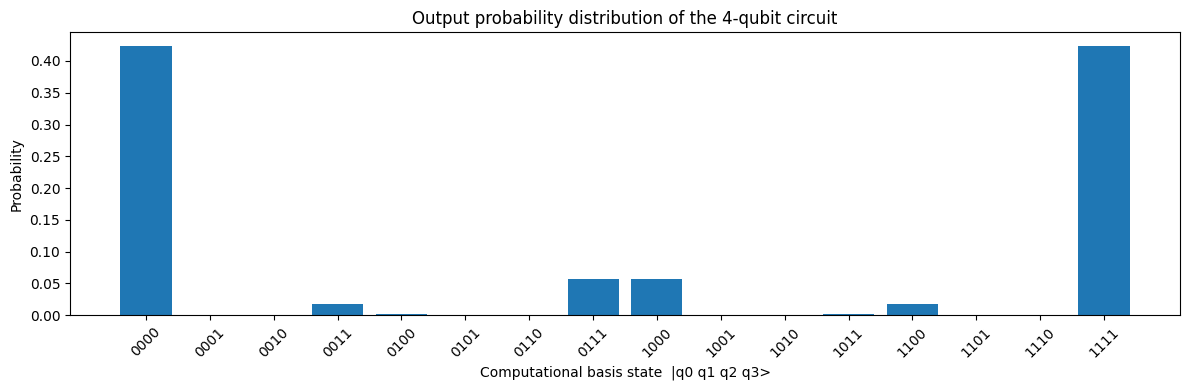

In [36]:
state = wavefunction(big_circuit, qpu)
probabilities = np.abs(state) ** 2
basis_states = [format(i, "04b") for i in range(2**big_circuit.nbqbits)]

print("Sum of all probabilities:", round(float(probabilities.sum()), 6), "(must always be 1)")

plt.figure(figsize=(12, 4))
plt.bar(basis_states, probabilities)
plt.xlabel("Computational basis state  |q0 q1 q2 q3>")
plt.ylabel("Probability")
plt.title("Output probability distribution of the 4-qubit circuit")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()